Import necessary packages.

In [1]:
# import all functions from python labrary: sympy
from sympy import *
# import python library: matplotlib (for nice plots)
import matplotlib
# set sympy output to print pretty math expressions
init_printing()

Declare variables we are going to use as 'symbols'. We will add more along the way, if necessary.

In [2]:
q1, q2, p1, p2, Ubar = symbols('q1 q2 p1 p2 \overline{U}')

<>:1: SyntaxWarning: invalid escape sequence '\o'
<>:1: SyntaxWarning: invalid escape sequence '\o'
/var/folders/8h/qk3v0tzx38s3f9x_dxz5wd2x22y8gc/T/ipykernel_13284/3667808122.py:1: SyntaxWarning: invalid escape sequence '\o'
  q1, q2, p1, p2, Ubar = symbols('q1 q2 p1 p2 \overline{U}')


# 4. Solve for cost-minimizing optimal consumption analytically

## Setup the optimization program

Given the CD utility function over two goods, our optimization problem is
\begin{align}
    & \min_{q_1,q_2} \quad p_1 q_1 + p_2 q_2 \\
    \text{s.t.}\quad & q_1^{\alpha} q_2^{1-\alpha} = \overline{U} 
\end{align}

$\min_{q_1,q_2}$

## Define notations in the utility function

In [3]:
# define alpha as a rational number of 1/2
#alpha = Rational(1,2)
# alpha = symbols('alpha')
alpha = Rational(2,5)
# define parameter beta as 1 - alpha
beta = 1 - alpha

## Setup the lagrangian

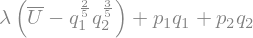

In [4]:
u = q1**(alpha) * q2**(beta)
lam = symbols('lambda')
lagr = p1*q1 + p2*q2 + lam *( Ubar - u )
lagr

Solve the first-order conditions. 

Note the syntax of the solve function, especially the use of the brackets:
solve( (eq1, eq2, eq3), var1, var2, var3)

The equations are by default treated as equal to 0 by the solver.



In [5]:
foc_sol = solve( ( diff(lagr,q1), diff(lagr,q2), diff(lagr,lam) ), q1,q2,lam)
foc_sol

The solution is not unique, some of them have imaginary values.

In [6]:
# how many solutions are there?
len(foc_sol)

Only the last solution is one with real values. 

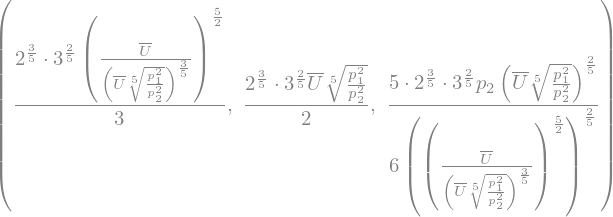

In [7]:
foc_sol[-1]

To access the first element in our solution, which is a list by itself, we use the list index again.

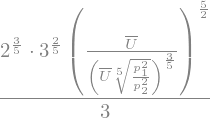

In [8]:
q1star = foc_sol[-1][0].simplify()
q1star

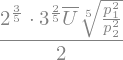

In [9]:
q2star = foc_sol[-1][1].simplify()
q2star

Substitute optimal consumption into the cost function, to calculate the optimal expenditure level attainable at the given exogenous variables. 

The resulting function is our **expenditure function**, $E(p_1,p_2,\bar{U})$.

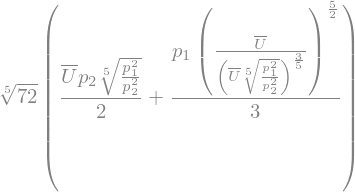

In [10]:
E = (p1*q1 + p2*q2).subs([(q1,q1star), (q2,q2star)]).simplify()
E

### Question: plotting Hicksian (compensated) demand curves
Given the Hicksian demand function derived above:
1. Plot the Hicksian demand curve for $q_1^*$ as a function of $p_1$, holding $p_2$ and $\overline{U}$ constant.
2. Compare two Hicksian demand curves as $\overline{U}$ changes.
3. Compare two Hicksian demand curves as $p_2$ changes.

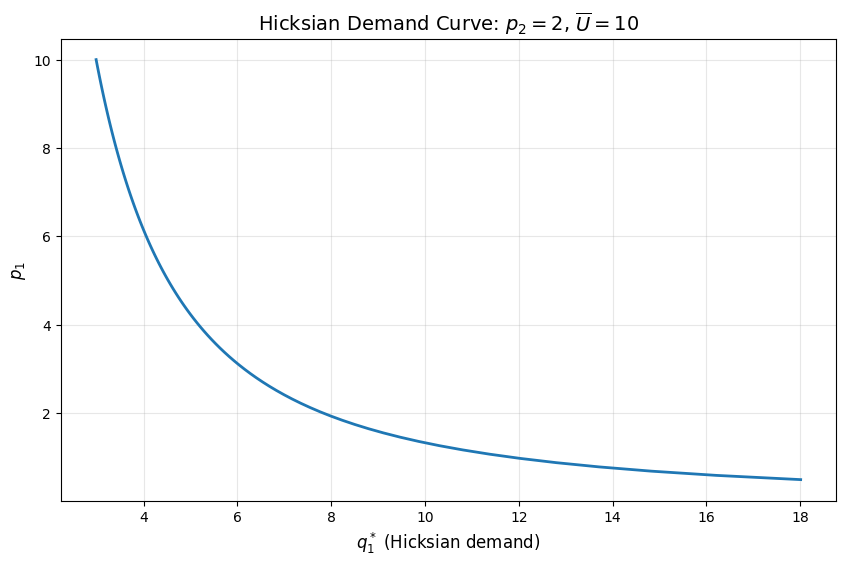

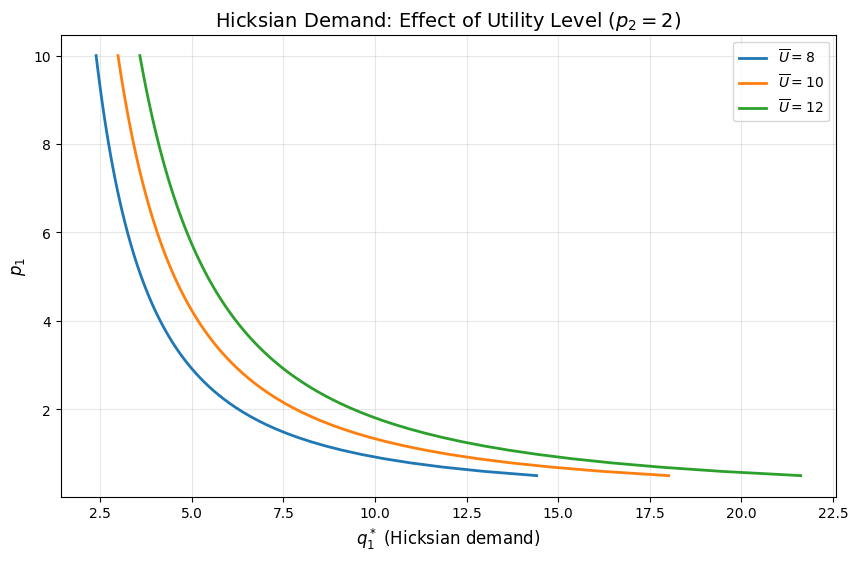

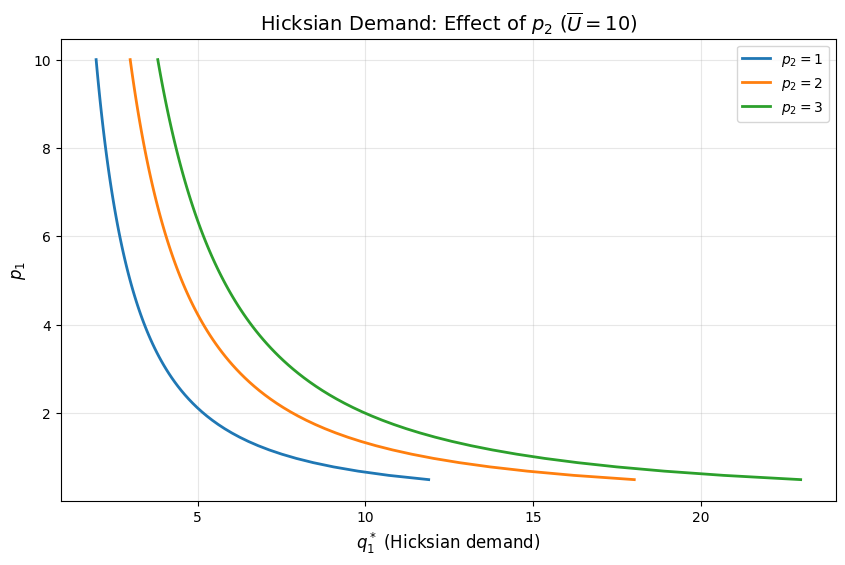

In [13]:
# 1. Plot Hicksian demand curve: q1* vs p1
# Set parameter values
p2_val = 2
Ubar_val = 10

# Create function for q1star with respect to p1
q1_p1 = lambdify(p1, q1star.subs([(p2, p2_val), (Ubar, Ubar_val)]), 'numpy')

# Plot
import numpy as np
import matplotlib.pyplot as plt

p1_range = np.linspace(0.5, 10, 100)
q1_range = q1_p1(p1_range)
plt.figure(figsize=(10, 6))
plt.plot(q1_range, p1_range, linewidth=2)
plt.xlabel('$q_1^*$ (Hicksian demand)', fontsize=12)
plt.ylabel('$p_1$', fontsize=12)
plt.title(f'Hicksian Demand Curve: $p_2={p2_val}$, $\\overline{{U}}={Ubar_val}$', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

# 2. Compare demand curves as Ubar changes
Ubar_vals = [8, 10, 12]
plt.figure(figsize=(10, 6))
for Ubar_val in Ubar_vals:
    q1_func = lambdify(p1, q1star.subs([(p2, p2_val), (Ubar, Ubar_val)]), 'numpy')
    q1_range = q1_func(p1_range)
    plt.plot(q1_range, p1_range, linewidth=2, label=f'$\\overline{{U}}={Ubar_val}$')
plt.xlabel('$q_1^*$ (Hicksian demand)', fontsize=12)
plt.ylabel('$p_1$', fontsize=12)
plt.title(f'Hicksian Demand: Effect of Utility Level ($p_2={p2_val}$)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Compare demand curves as p2 changes
Ubar_val = 10
p2_vals = [1, 2, 3]
plt.figure(figsize=(10, 6))
for p2_val in p2_vals:
    q1_func = lambdify(p1, q1star.subs([(p2, p2_val), (Ubar, Ubar_val)]), 'numpy')
    q1_range = q1_func(p1_range)
    plt.plot(q1_range, p1_range, linewidth=2, label=f'$p_2={p2_val}$')
plt.xlabel('$q_1^*$ (Hicksian demand)', fontsize=12)
plt.ylabel('$p_1$', fontsize=12)
plt.title(f'Hicksian Demand: Effect of $p_2$ ($\\overline{{U}}={Ubar_val}$)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Question: plotting quantity-utility relationship
1. Plot $q_1^*$ as a function of $\overline{U}$, holding prices constant.
2. Compare two curves as $p_1$ changes.
3. Compare two curves as $p_2$ changes.

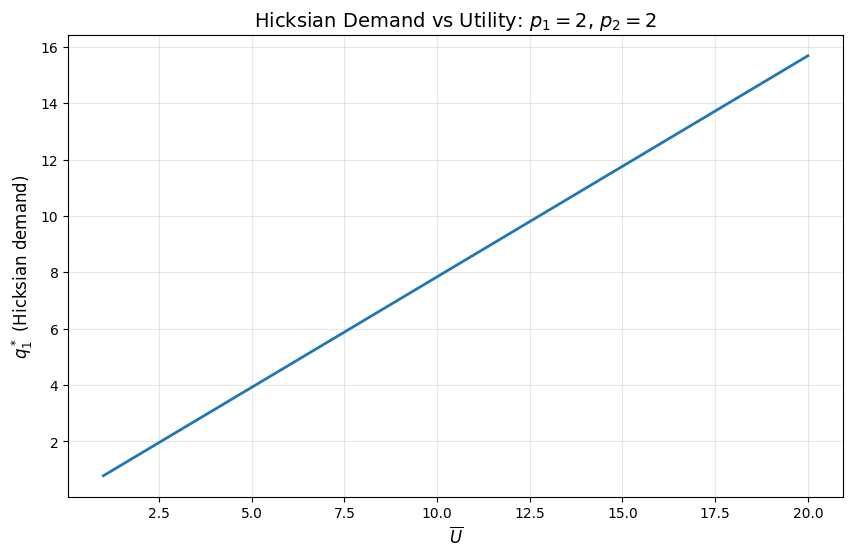

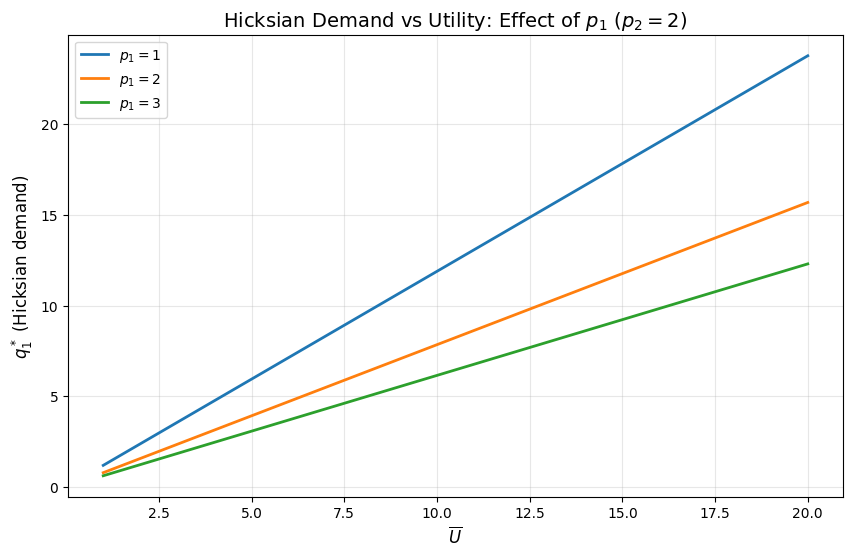

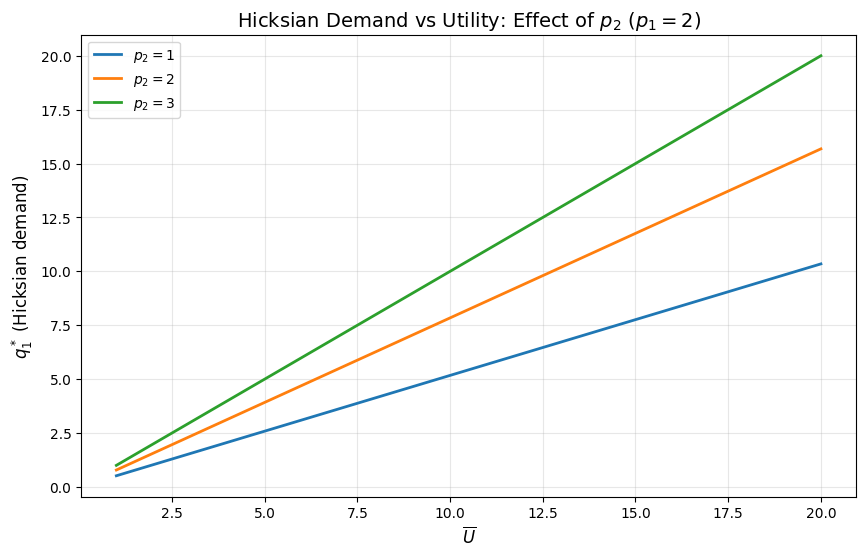

In [12]:
# 1. Plot q1* vs Ubar
p1_val = 2
p2_val = 2

q1_Ubar = lambdify(Ubar, q1star.subs([(p1, p1_val), (p2, p2_val)]), 'numpy')

Ubar_range = np.linspace(1, 20, 100)
plt.figure(figsize=(10, 6))
plt.plot(Ubar_range, q1_Ubar(Ubar_range), linewidth=2)
plt.xlabel('$\\overline{U}$', fontsize=12)
plt.ylabel('$q_1^*$ (Hicksian demand)', fontsize=12)
plt.title(f'Hicksian Demand vs Utility: $p_1={p1_val}$, $p_2={p2_val}$', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

# 2. Compare as p1 changes
p2_val = 2
p1_vals = [1, 2, 3]
plt.figure(figsize=(10, 6))
for p1_val in p1_vals:
    q1_func = lambdify(Ubar, q1star.subs([(p1, p1_val), (p2, p2_val)]), 'numpy')
    plt.plot(Ubar_range, q1_func(Ubar_range), linewidth=2, label=f'$p_1={p1_val}$')
plt.xlabel('$\\overline{U}$', fontsize=12)
plt.ylabel('$q_1^*$ (Hicksian demand)', fontsize=12)
plt.title(f'Hicksian Demand vs Utility: Effect of $p_1$ ($p_2={p2_val}$)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Compare as p2 changes
p1_val = 2
p2_vals = [1, 2, 3]
plt.figure(figsize=(10, 6))
for p2_val in p2_vals:
    q1_func = lambdify(Ubar, q1star.subs([(p1, p1_val), (p2, p2_val)]), 'numpy')
    plt.plot(Ubar_range, q1_func(Ubar_range), linewidth=2, label=f'$p_2={p2_val}$')
plt.xlabel('$\\overline{U}$', fontsize=12)
plt.ylabel('$q_1^*$ (Hicksian demand)', fontsize=12)
plt.title(f'Hicksian Demand vs Utility: Effect of $p_2$ ($p_1={p1_val}$)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()